# Traffic Congestion Prediction and Route Optimisation using Machine Learning
**ML-II Project-Based Assignment (Project 3, CO3 | L6): Phase 2 implementation**
Akshitha · Dept. of AI & ML · CMR Institute of Technology, Bengaluru

| Assignment requirement | Section |
|---|---|
| Collect traffic volume and road-network datasets | 1, 7 |
| Pre-processing and exploratory data analysis | 1, 2 |
| Clustering to identify congestion zones | 3 |
| Predict traffic conditions from historical data | 4, 5 |
| Recommend alternative routes from predicted congestion | 7 |
| Evaluate effectiveness | 4-7, 8 |
| Role in smart transportation | 9 |

In [1]:
import sys, json, warnings
import torch  # import before XGBoost (avoids an OpenMP deadlock on macOS)
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src import eda, clustering as CL, models as M, routing as R, plots_routing as PR
from src.config import FIG_DIR, CLASS_NAMES
from src.data import build_dataset, data_quality_report, split_masks
show = lambda n, w=900: display(Image(filename=str(FIG_DIR / n), width=w))

## 1. Data collection and pre-processing
**Traffic volume dataset:** Kaggle *Traffic Prediction Dataset* (fedesoriano): hourly vehicle counts at 4 urban junctions, Nov 2015 to Jun 2017 (48,120 rows; Junction 4 only from Jan 2017).
**Road-network dataset:** a 21-junction / 33-link Bengaluru graph with real approximate coordinates (Section 7).

**Pre-processing steps**
1. Reindex every junction to a complete hourly grid; interpolate gaps (none found).
2. Outliers: spikes above Q3 + 3·IQR (mostly Junction 3) are **kept in the label** (a real spike is real congestion), but **clipped for features** at the rolling 99.5th percentile.
3. **Congestion label (volume-to-capacity).** Capacity = the junction's 95th-percentile hourly volume over the *previous* 28 days. V/C = vehicles / capacity, giving **Low < 0.50 ≤ Moderate < 0.80 ≤ High**. A rolling, past-only capacity removes the strong growth trend and never looks into the future.
4. **Features at hour t, used to predict hour t+1:**
   - cyclic hour and day (sin/cos), weekend and peak flags
   - V/C lags (1, 2, 3, 23 and 167 h, i.e. same hour yesterday and last week)
   - rolling mean/std over 3 h and 24 h, plus volume lags
   - capacity, junction one-hot
   - the junction × hour-of-week historical V/C (computed on training data only)
   - the K-Means hotspot zone (Section 3)

In [2]:
raw, df, model_df, feats, _ = build_dataset()
print(raw.shape, "->", model_df.shape, "usable modelling rows")
data_quality_report(raw)

(48120, 4) -> (46776, 47) usable modelling rows


,junction,start,end,rows,missing_hours,null_values,duplicates,mean_vehicles,max_vehicles,extreme_spikes(>Q3+3IQR)
0,1,2015-11-01,2017-06-30 23:00:00,14592,0,0,0,45.05,156,1
1,2,2015-11-01,2017-06-30 23:00:00,14592,0,0,0,14.25,48,38
2,3,2015-11-01,2017-06-30 23:00:00,14592,0,0,0,13.69,180,143
3,4,2017-01-01,2017-06-30 23:00:00,4344,0,0,0,7.25,36,21


In [3]:
raw.head()

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


## 2. Exploratory data analysis

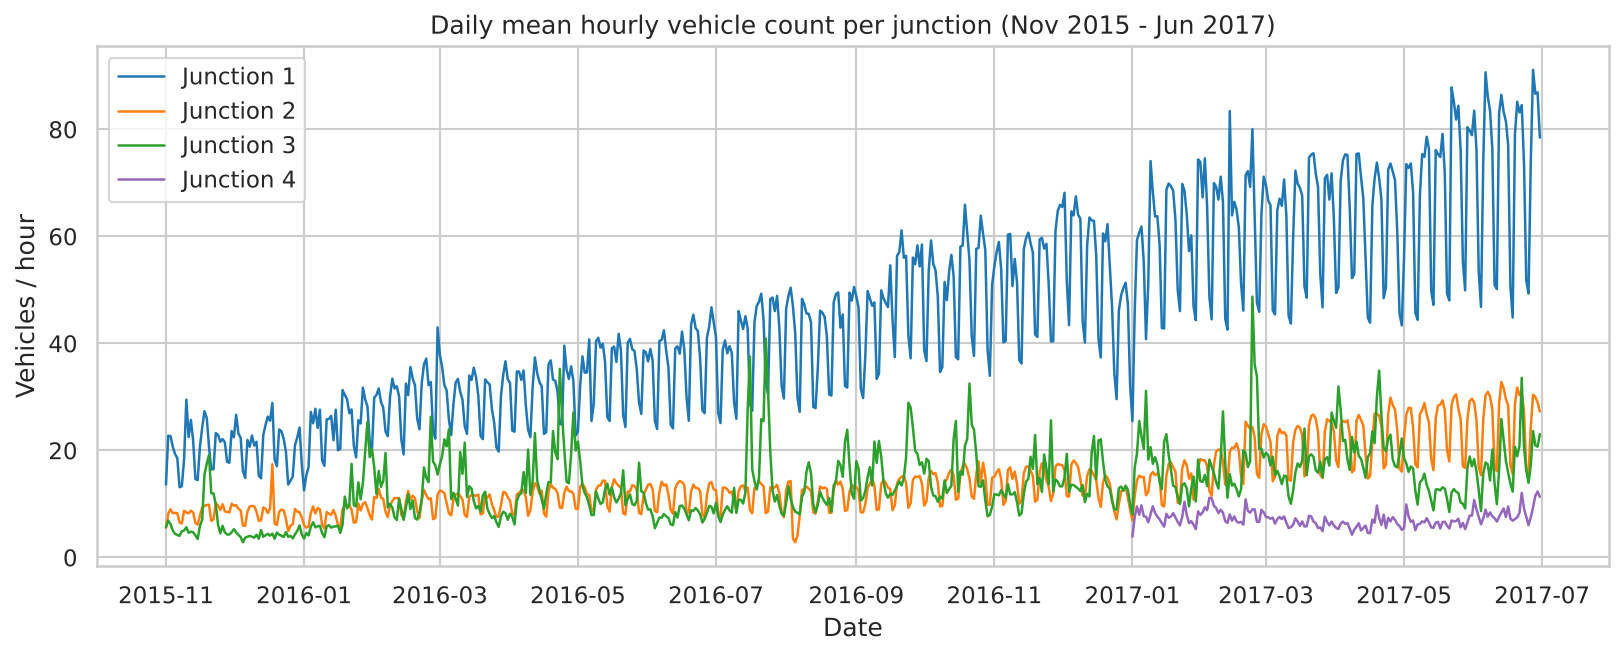

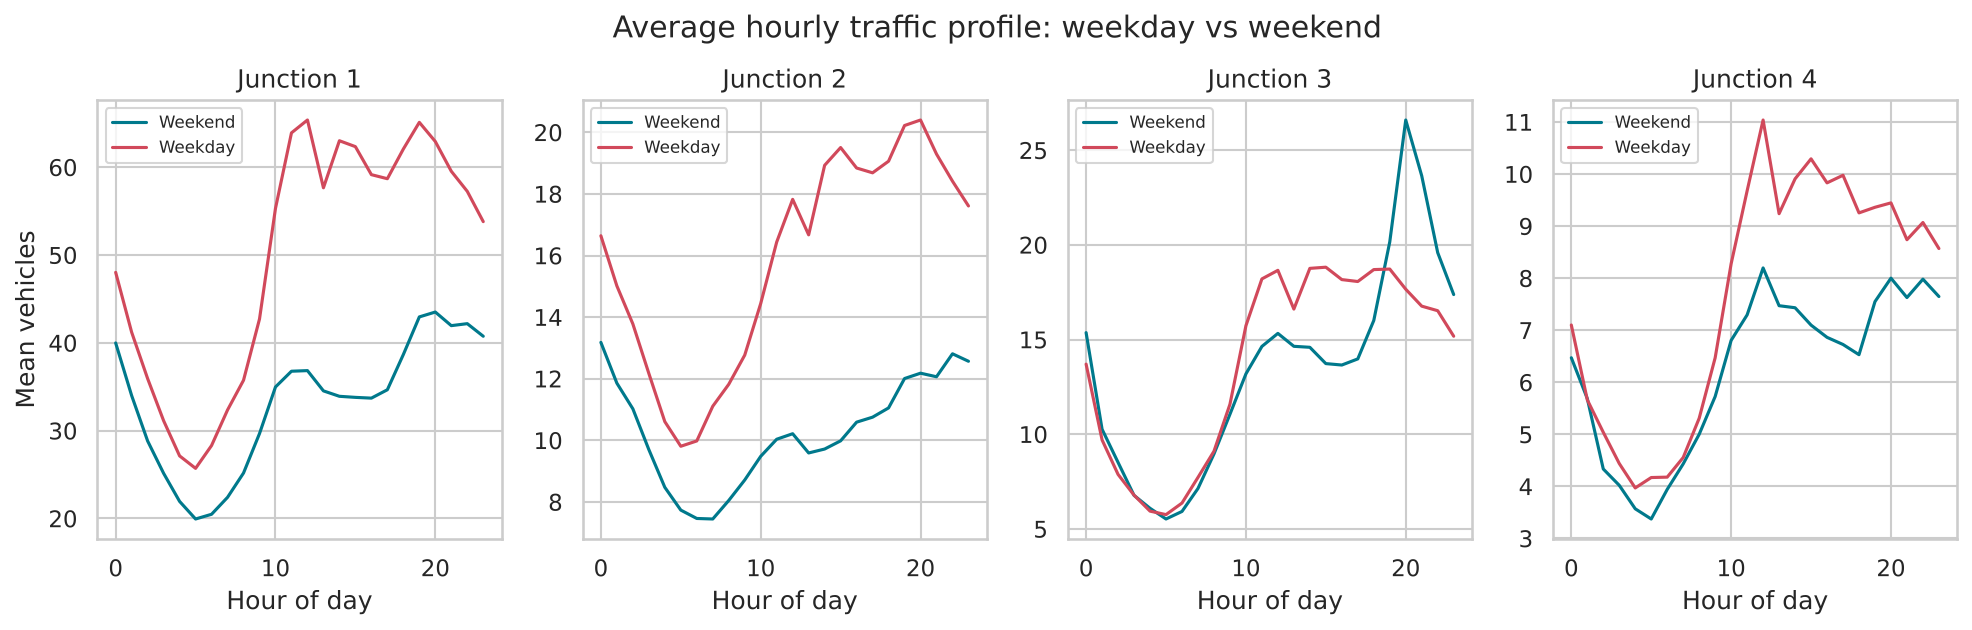

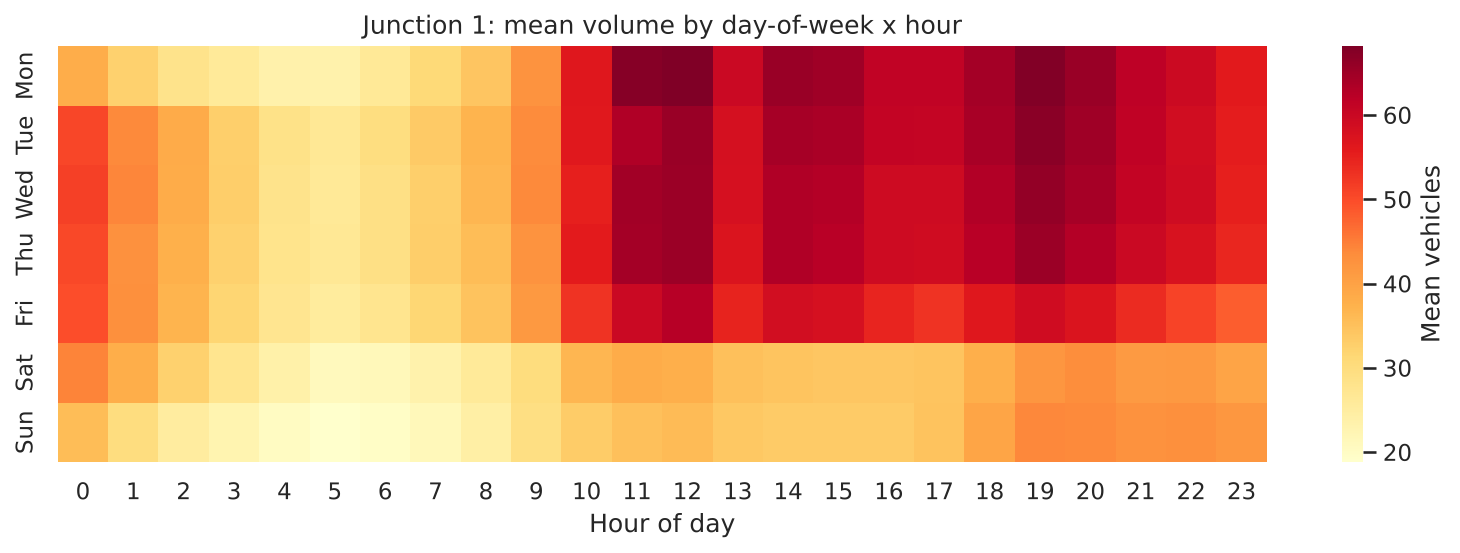

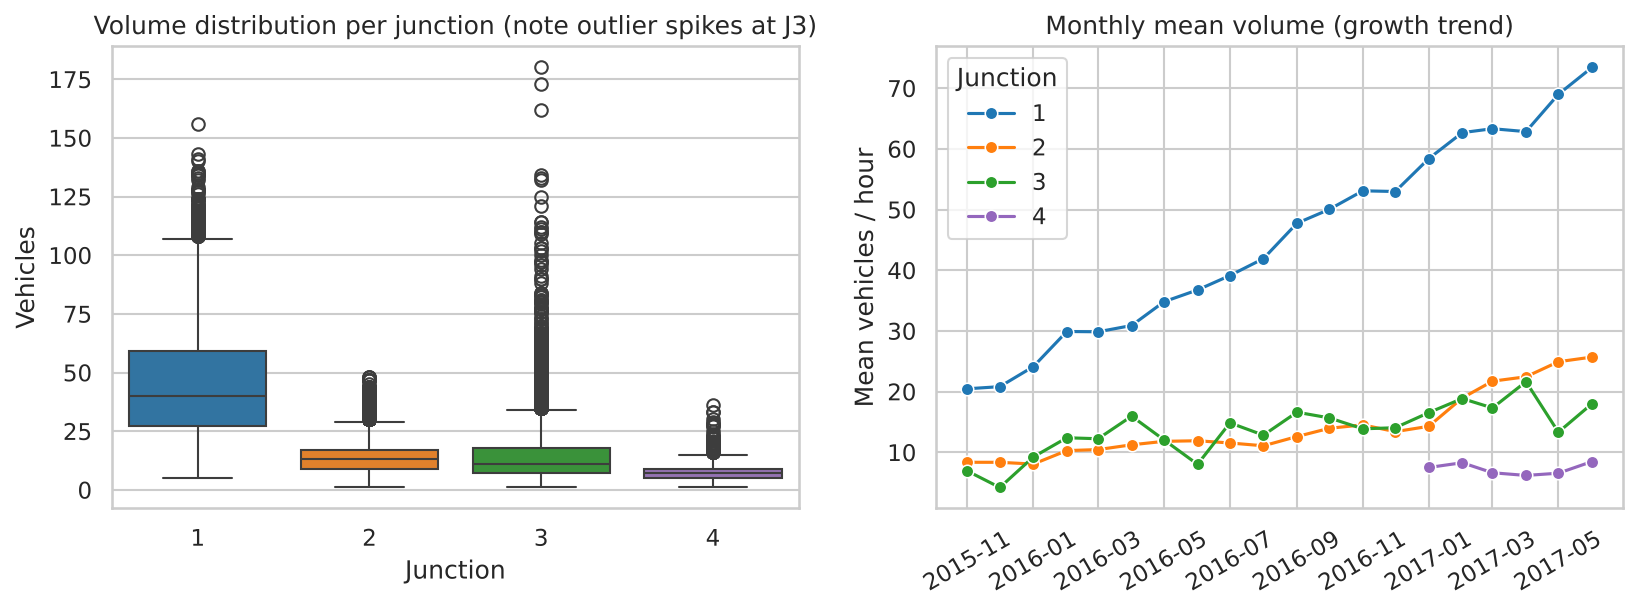

In [4]:
eda.run_all(raw, df, model_df, feats)
for n in ["01_daily_trend.png", "02_hourly_profile.png", "03_heatmap_dow_hour_j1.png", "04_distribution_growth.png"]:
    show(n)

**Observations**
- **Strong growth trend:** Junction 1 volume roughly doubles over the 20 months. This is why congestion is defined *relative to recent capacity*, not with a fixed threshold.
- **Clear daily cycle:** traffic is low from 1–7 am and peaks from late morning through the evening.
- **Weekends are much lighter** at Junctions 1 and 2.
- **Junction 3 has extreme event-like spikes** (non-recurrent congestion).
- **Junction 4 is low-volume** and has only 6 months of history.

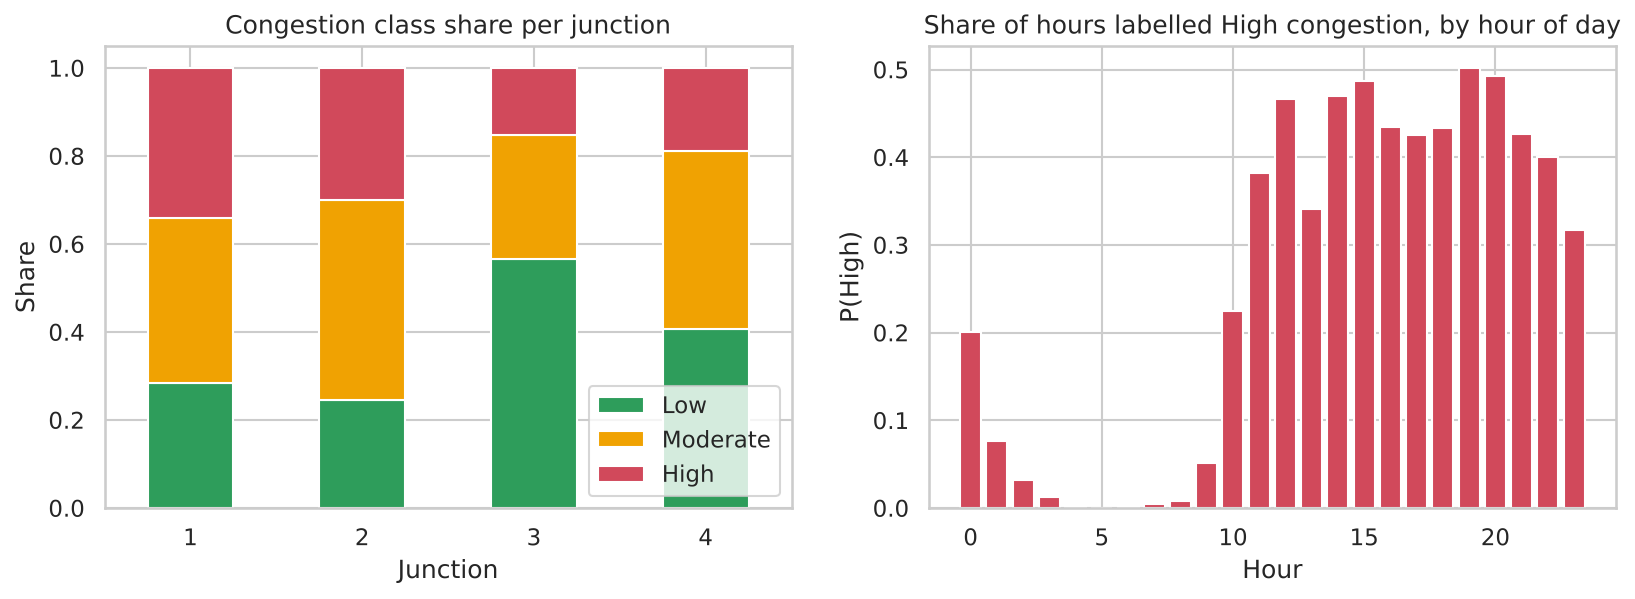

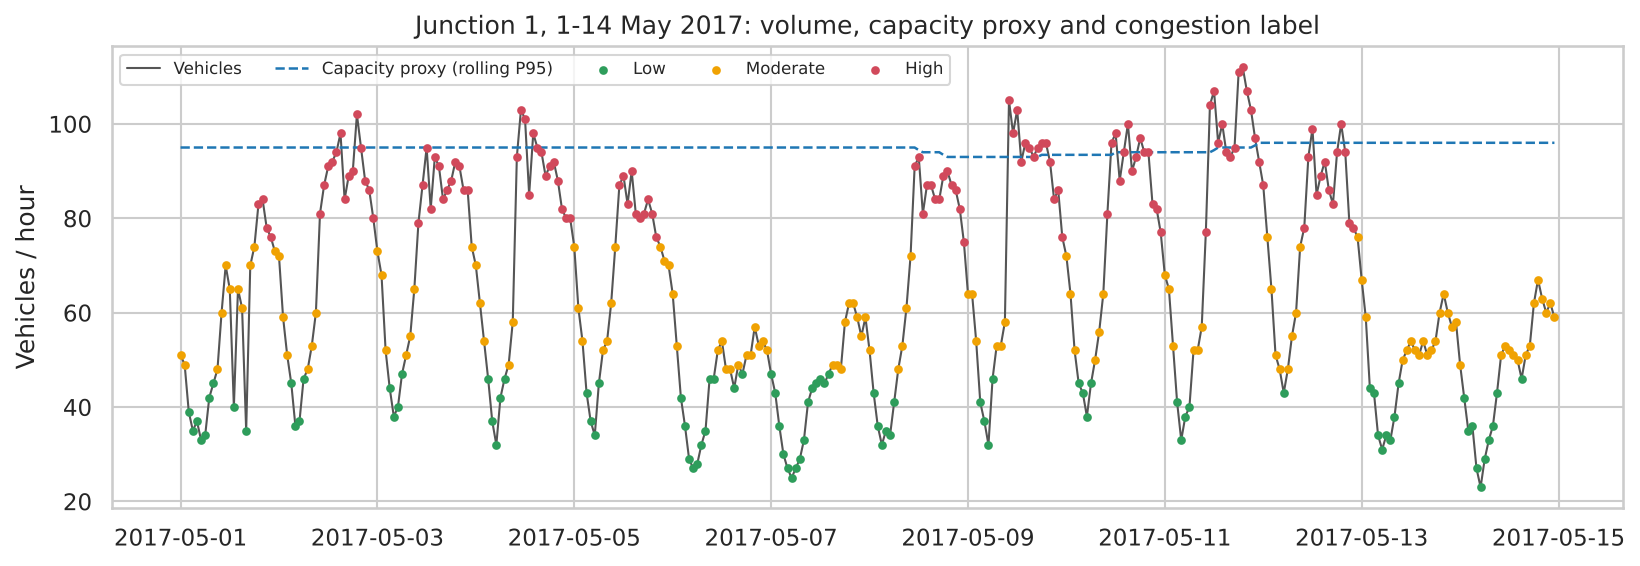

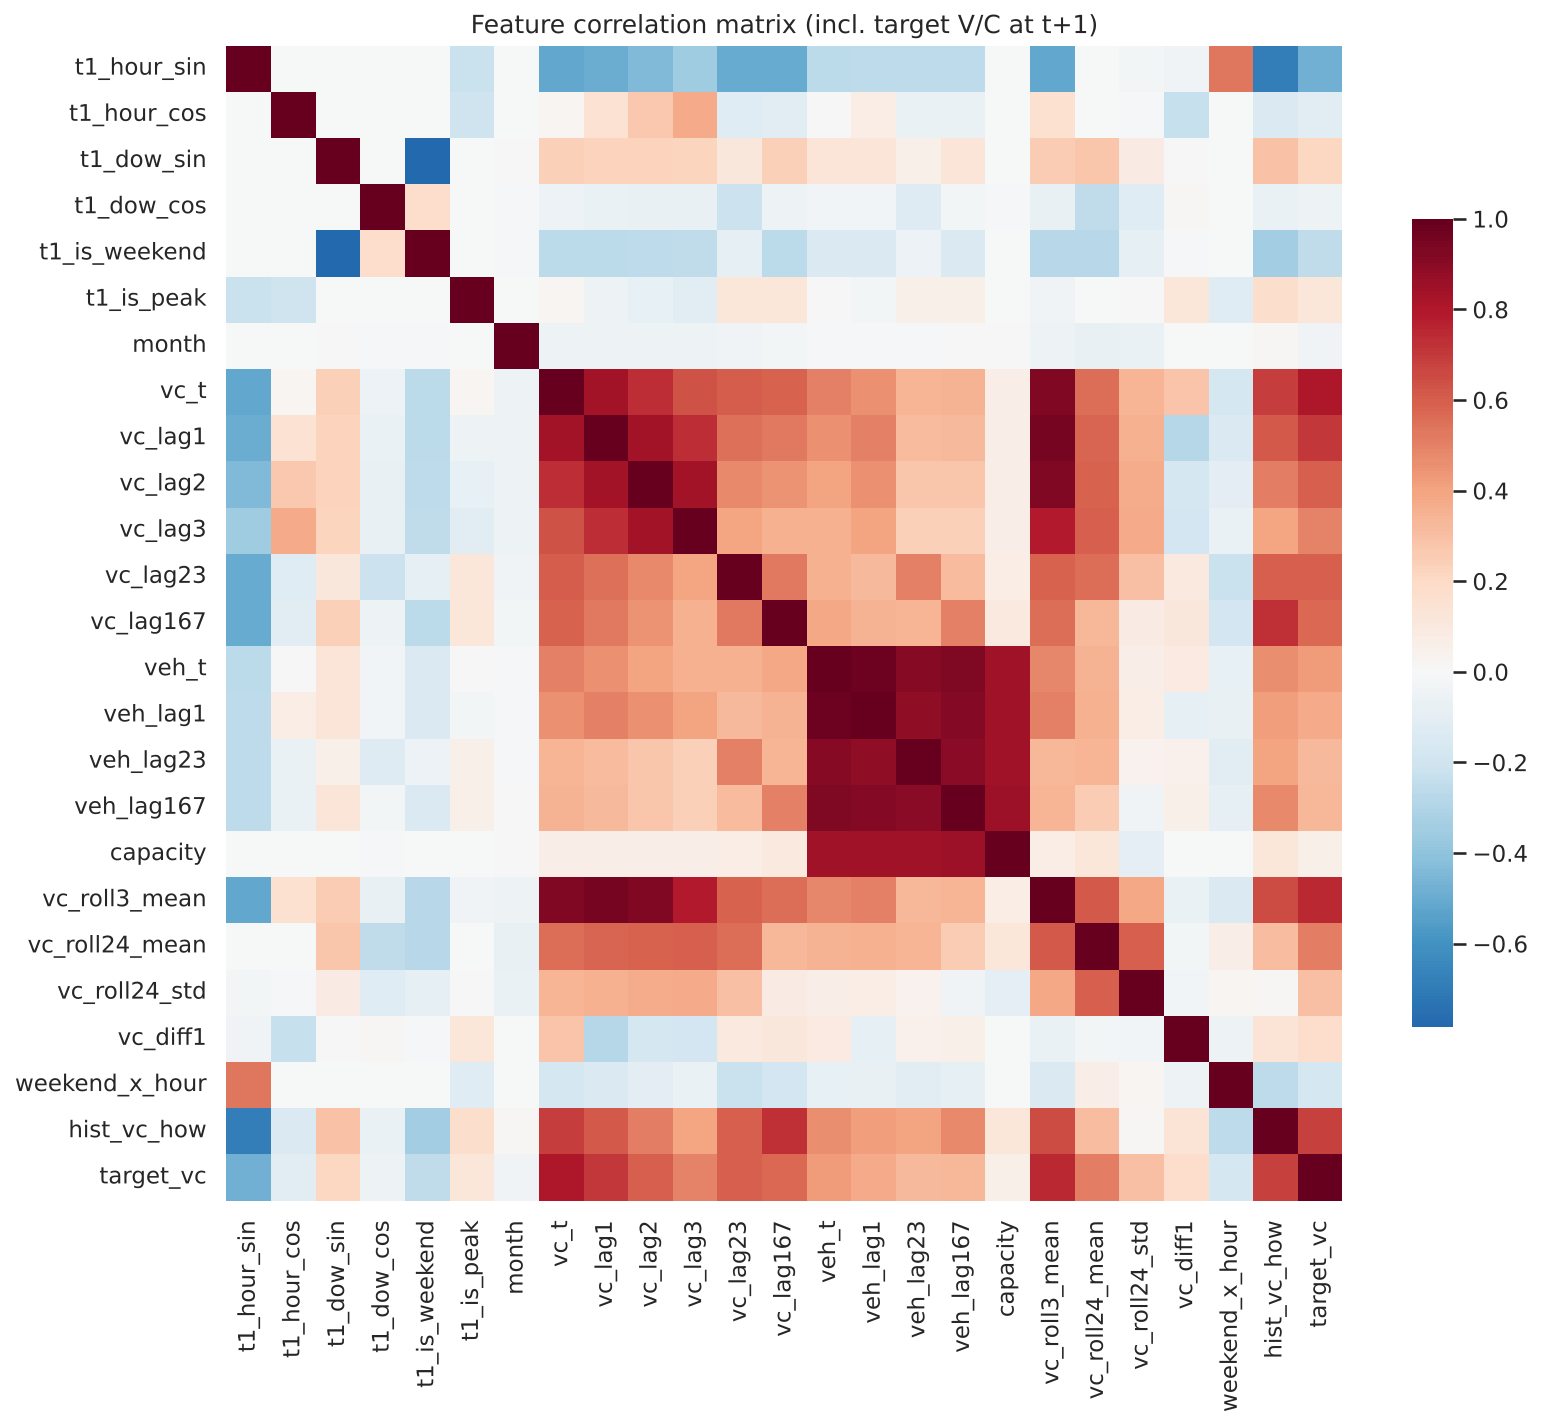

In [5]:
for n in ["05_label_distribution.png", "06_vc_label_example.png", "07_feature_correlation.png"]:
    show(n)

## 3. Clustering: congestion zones (hotspots)
Each point is one **(junction, hour-of-week)** slot, giving 4 × 168 = 672 points. Each slot is described by its *training-period* mean V/C, 90th-percentile V/C, std, P(High) and relative volume. The features are standardised, then clustered with **K-Means** (k chosen using elbow, silhouette, Davies-Bouldin and Calinski-Harabasz) and **DBSCAN** (eps tuned on the k-distance curve).

In [6]:
tr_full, _, _ = split_masks(df)
cres = CL.run_clustering(df, tr_full, k=3)
CL.plot_selection(cres); CL.plot_zones(cres); CL.plot_pca(cres)
display(cres["selection"].round(3)); print("K-Means:", cres["kmeans"], "\nDBSCAN:", cres["dbscan"])
display(cres["zone_summary"]); display(cres["zone_by_junction"])

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,1505.366,0.515,0.750,825.450
1,3,1070.206,0.506,0.845,715.690
2,4,774.241,0.468,0.794,743.647
3,5,557.624,0.462,0.683,838.013
4,6,431.704,0.427,0.717,903.510
5,7,365.093,0.417,0.752,909.179
6,8,299.294,0.400,0.764,970.084


K-Means: {'k': 3, 'silhouette': 0.506, 'davies_bouldin': 0.845} 
DBSCAN: {'eps': 0.617, 'min_samples': 5, 'n_clusters': 3, 'noise_points': 20, 'silhouette_excl_noise': 0.032}


,slots,mean_vc,p_high,rel_volume
zone_name,,,,
Free-flow zone,347,0.454,0.023,0.736
Moderate zone,160,0.673,0.250,1.235
Hotspot zone,165,0.858,0.671,1.327


zone_name,Free-flow zone,Moderate zone,Hotspot zone
Junction,,,
1,96,0,72
2,90,12,66
3,70,98,0
4,91,50,27


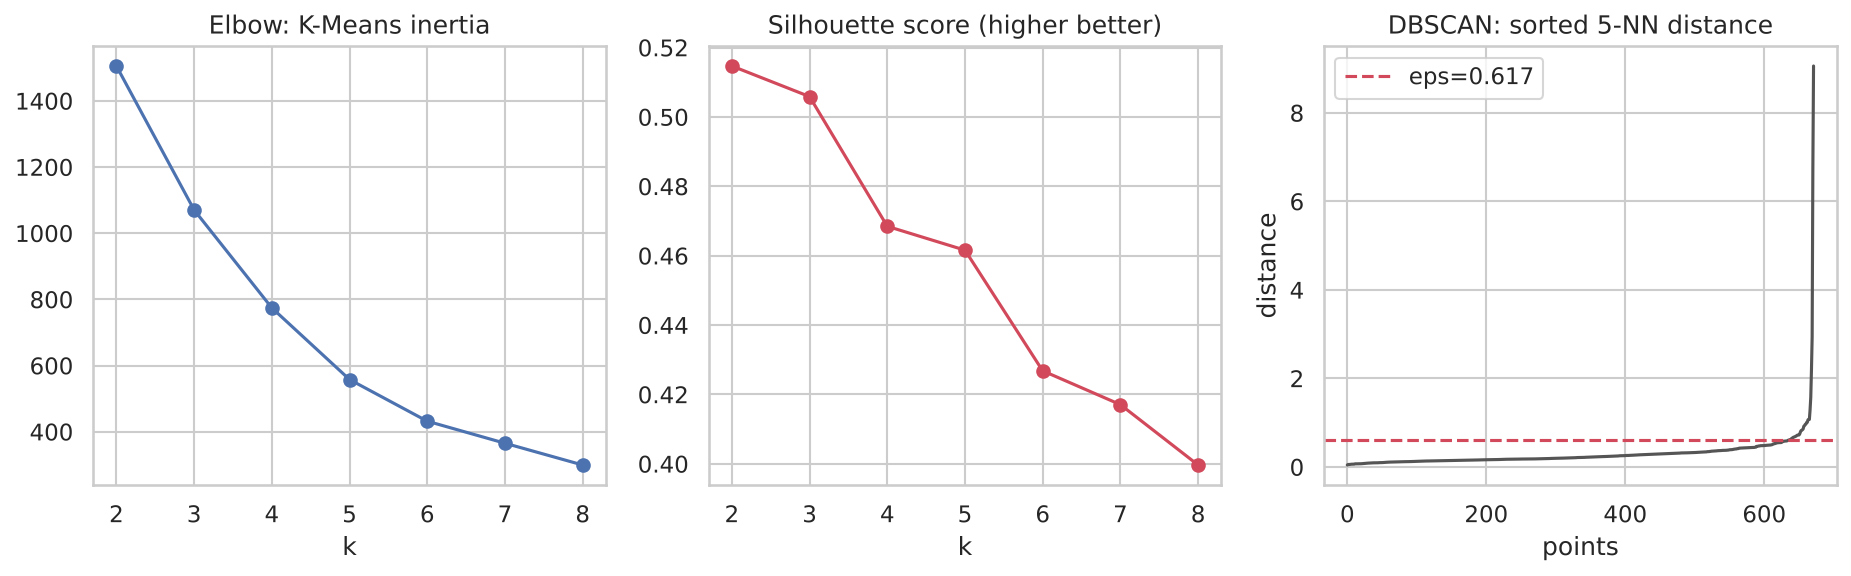

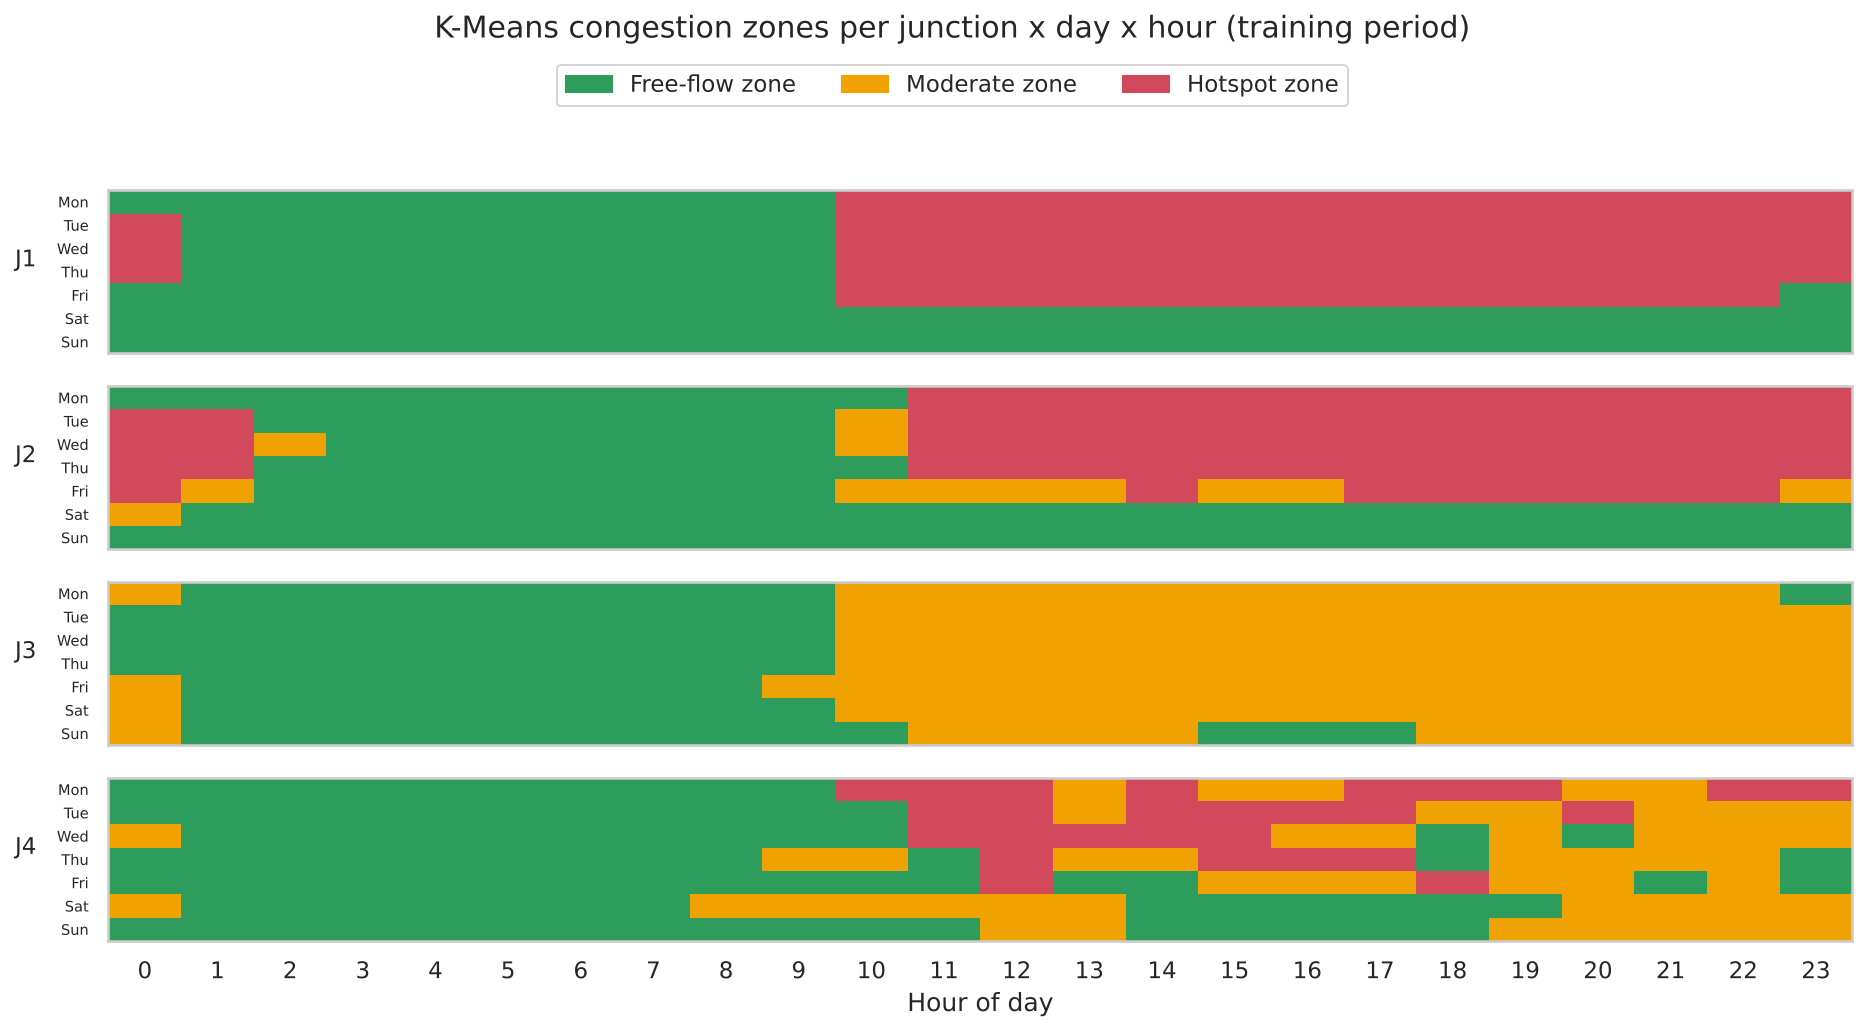

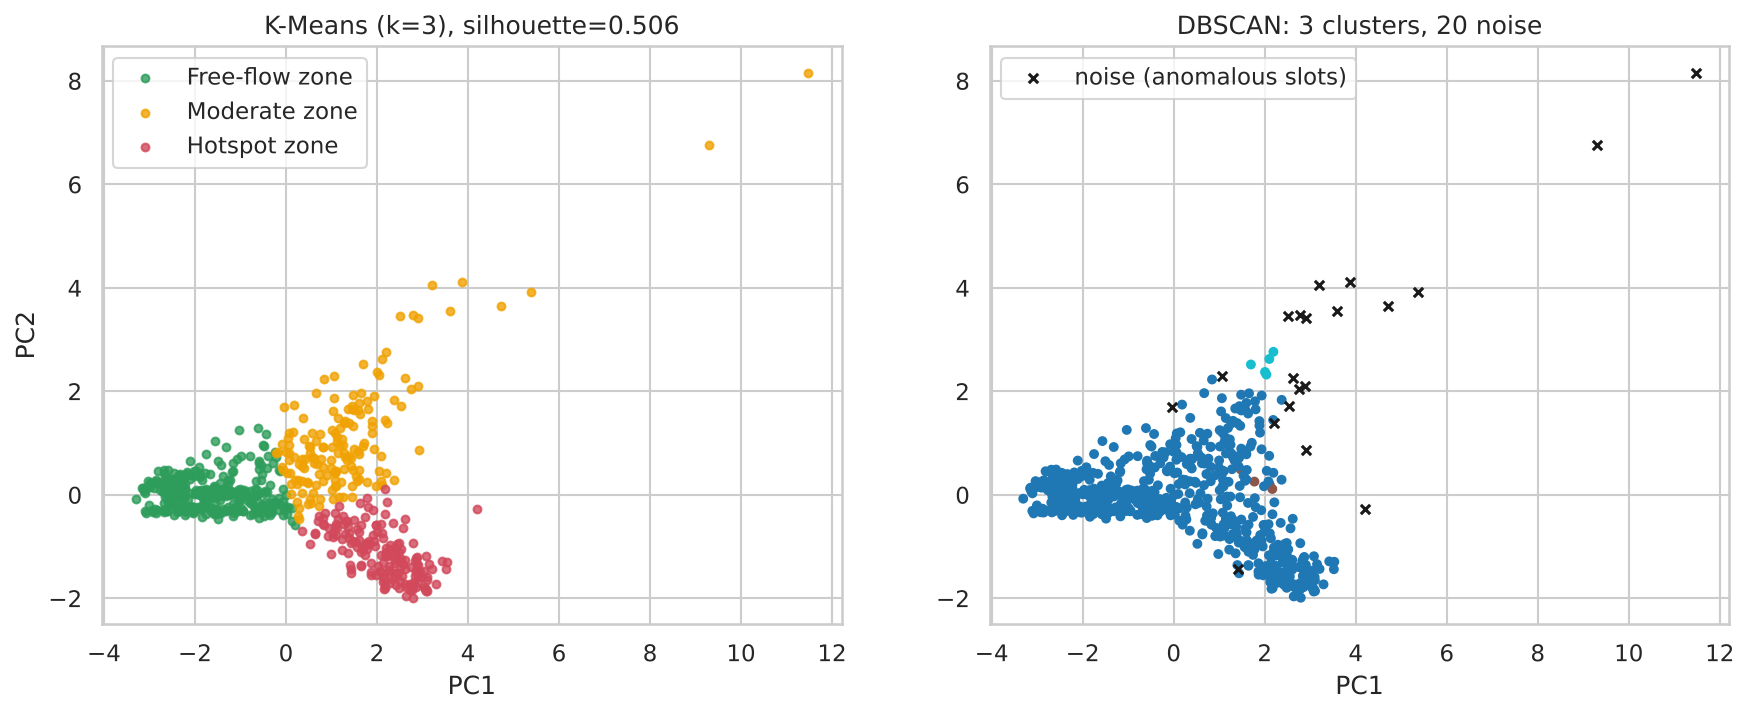

In [7]:
for n in ["08_cluster_selection.png", "09_congestion_zones.png", "10_cluster_pca.png"]:
    show(n)

**Interpretation**
- **Choice of k = 3:** k = 2 has a marginally higher silhouette (0.515 vs 0.506), but k = 3 is almost as compact and gives three operationally meaningful tiers: free-flow, moderate and hotspot.
- **Hotspot slots:** weekday daytime and evening at Junctions 1 and 2 (P(High) ≈ 0.67).
- **Junction 3** is mostly a *moderate* zone.
- **DBSCAN:** the slots form one dense continuum, so DBSCAN finds one large cluster plus a few tiny ones (silhouette ≈ 0.03). Its main value is the **noise points**, i.e. anomalous slots. K-Means is better suited to zoning.
- **Link to prediction:** the zone of the target slot is fed to the predictors as a feature (`hotspot_zone`).

## 4. Predicting congestion (t+1 hour)
**Chronological split** (no shuffling, no leakage):
- train: Nov 2015 – Feb 2017
- validation: Mar 2017 (XGBoost early stopping, LSTM early stopping)
- test: Apr – Jun 2017

**Models**
- Persistence (naive: next hour = this hour)
- Historical average (junction × hour-of-week profile)
- Logistic Regression
- Random Forest
- XGBoost
- LSTM (Section 5)

In [8]:
model_df = CL.zone_feature(model_df, cres["profiles"]); feats = feats + ["hotspot_zone"]
train, val, test = split_masks(model_df)
print("train", train.sum(), "val", val.sum(), "test", test.sum())
print(model_df.loc[test, "target_class"].value_counts(normalize=True).sort_index().rename(index=dict(enumerate(CLASS_NAMES))).round(3))
cls, preds, models, info = M.train_classifiers(model_df, feats, train, val, test)
print(info); cls.round(3)

train 35068 val 2976 test 8732
target_class
Low         0.376
Moderate    0.352
High        0.272
Name: proportion, dtype: float64


{'xgb_best_n_estimators': 429}


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,recall_high,train_seconds
0,Persistence (naive),0.713,0.716,0.716,0.716,0.713,0.770,NaN
1,Historical average,0.709,0.746,0.702,0.713,0.714,0.622,NaN
2,Logistic Regression,0.774,0.782,0.773,0.777,0.775,0.773,1.678
3,Random Forest,0.789,0.797,0.788,0.792,0.790,0.796,16.317
4,XGBoost,0.790,0.802,0.788,0.793,0.792,0.770,11.029


## 5. LSTM extension (sequence model)

**Inputs**
- the last 24 hours of V/C and time encodings per junction, fed to a 2-layer LSTM (64 units)
- static context: target-hour encodings, historical profile, hotspot zone, junction

**Training:** class-weighted cross-entropy, Adam, early stopping on the validation month.

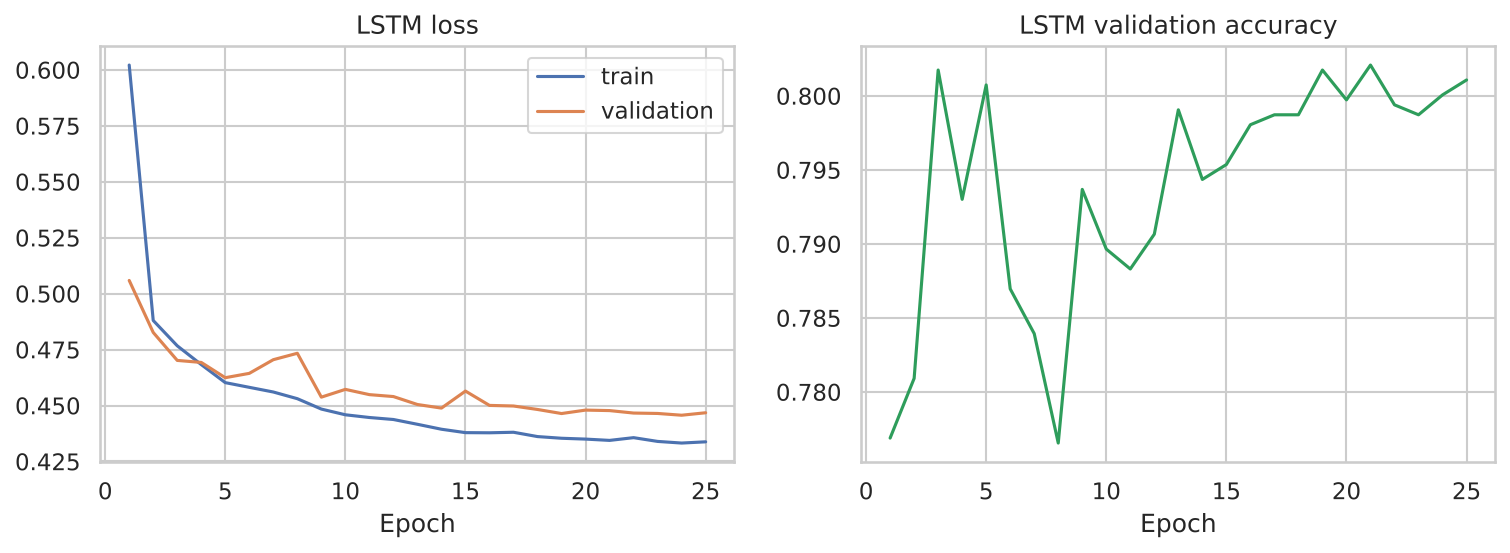

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,recall_high,train_seconds
0,Persistence (naive),0.713,0.716,0.716,0.716,0.713,0.770,NaN
1,Historical average,0.709,0.746,0.702,0.713,0.714,0.622,NaN
2,Logistic Regression,0.774,0.782,0.773,0.777,0.775,0.773,1.678
3,Random Forest,0.789,0.797,0.788,0.792,0.790,0.796,16.317
4,XGBoost,0.790,0.802,0.788,0.793,0.792,0.770,11.029
5,LSTM,0.787,0.786,0.791,0.788,0.786,0.855,159.451


In [9]:
from src import lstm_model as L
out = L.train_lstm(full_df=df, model_df=model_df, train=train, val=val, test=test, verbose=False)
preds["LSTM"] = out["pred"]
cls = pd.concat([cls, pd.DataFrame([M.clf_metrics("LSTM", out["y"], out["pred"], out["train_seconds"])])], ignore_index=True)
PR.plot_lstm_history(out["history"]); show("19_lstm_training.png", 800)
cls.round(3)

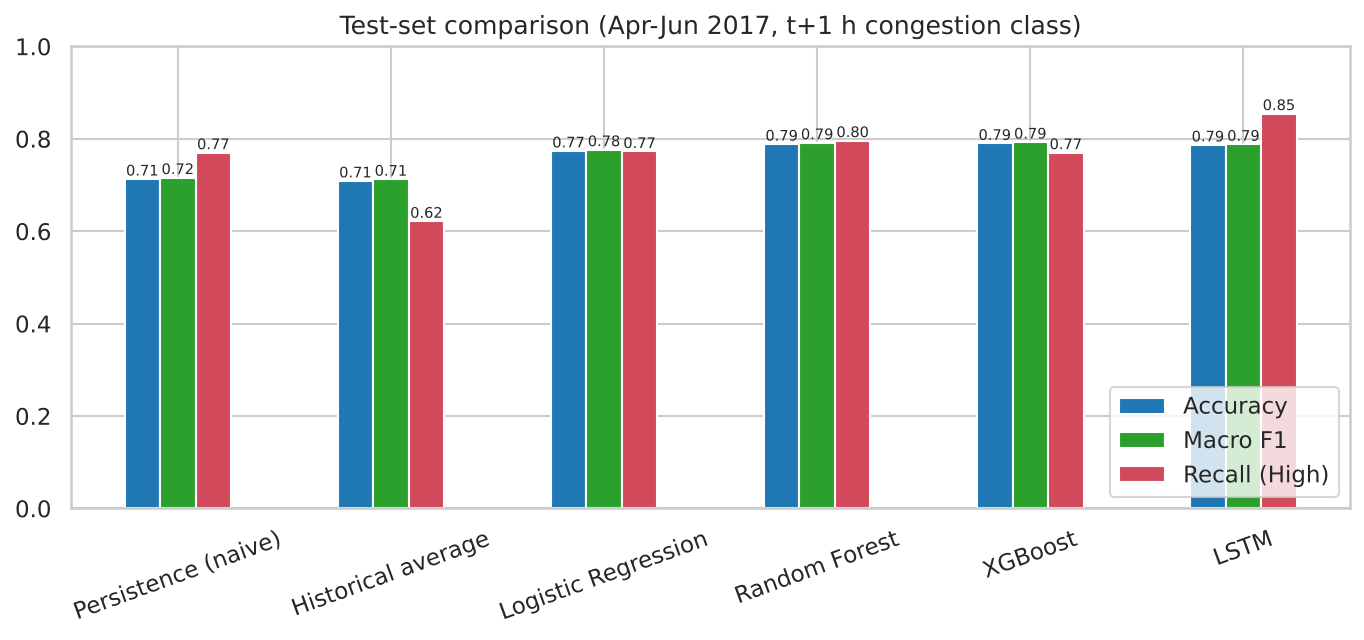

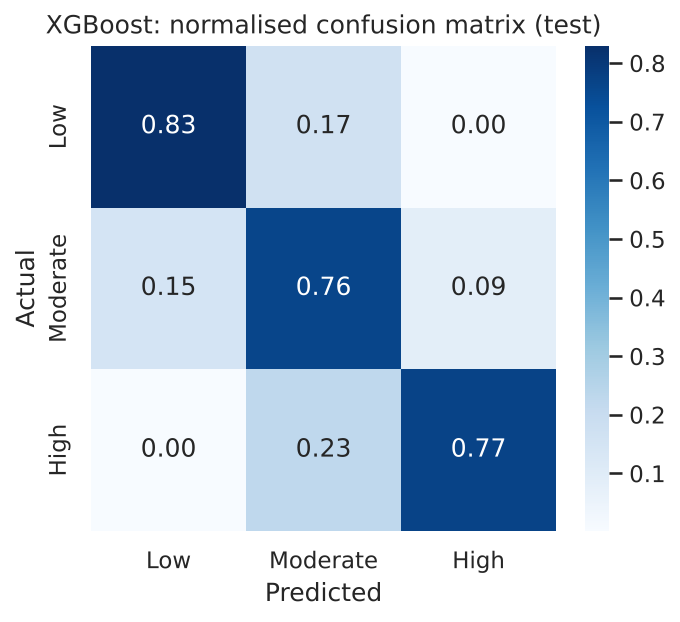

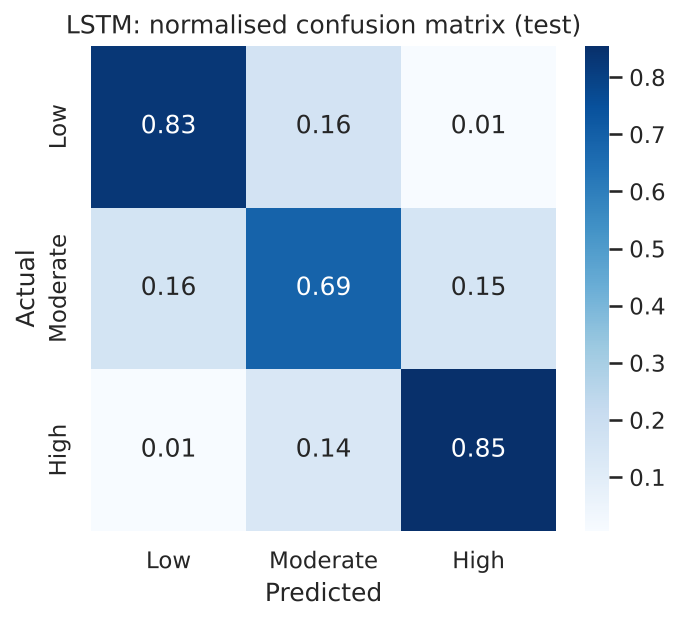

              precision    recall  f1-score   support

         Low       0.85      0.83      0.84      3279
    Moderate       0.68      0.76      0.72      3077
        High       0.87      0.77      0.82      2376

    accuracy                           0.79      8732
   macro avg       0.80      0.79      0.79      8732
weighted avg       0.80      0.79      0.79      8732



In [10]:
yte = model_df.loc[test, "target_class"].values
M.plot_model_comparison(cls); M.plot_confusion(yte, preds["XGBoost"], "XGBoost", "12_confusion_xgboost.png")
M.plot_confusion(out["y"], out["pred"], "LSTM", "12b_confusion_lstm.png")
show("11_model_comparison.png"); show("12_confusion_xgboost.png", 450); show("12b_confusion_lstm.png", 450)
print(M.classification_report(yte, preds["XGBoost"], target_names=CLASS_NAMES))

,accuracy,f1_macro,persistence_f1_macro
Junction,,,
1,0.912,0.912,0.821
2,0.821,0.825,0.762
3,0.814,0.781,0.722
4,0.613,0.601,0.516


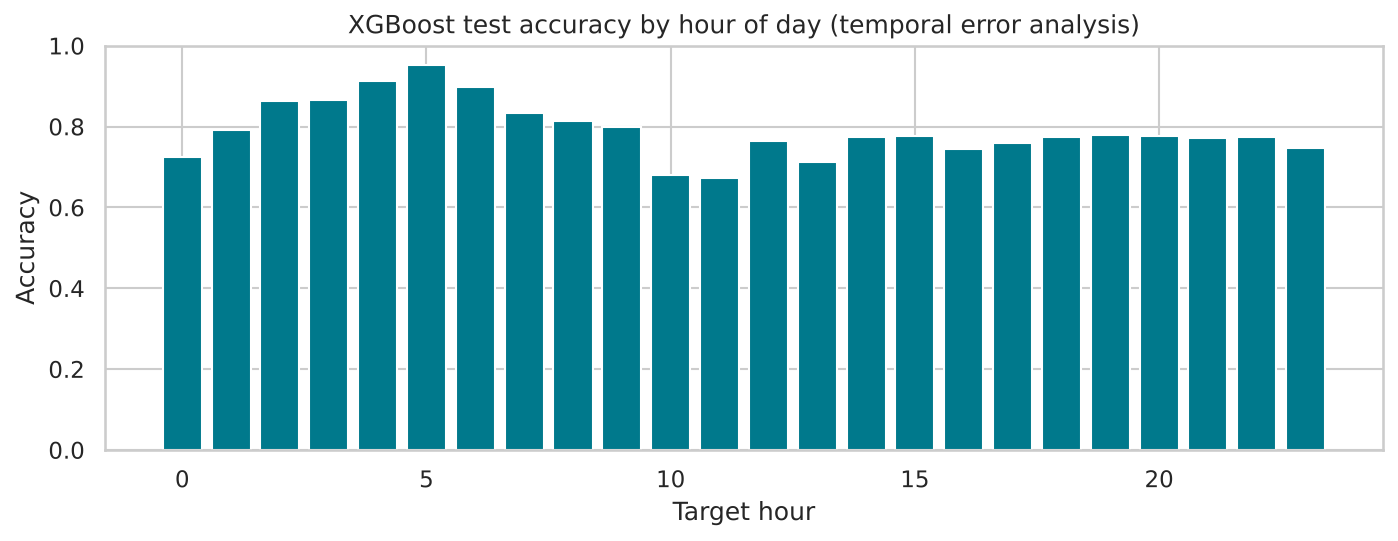

In [11]:
display(M.per_junction_report(model_df, test, preds))
M.plot_hour_error(M.per_hour_error(model_df, test, preds)); show("13_error_by_hour.png")

**Results**
- **XGBoost and Random Forest:** about 79% accuracy and 0.79 macro-F1, against 71% / 0.72 for persistence. That is a gain of about 8 points over the naive forecast.
- **LSTM:** comparable accuracy and the **best High-congestion recall** (≈0.85). It catches more jams at the cost of more false alarms.
- **Per junction:** Junction 1 (regular, high volume) reaches about 91%. Junction 4 (6 months of data, low volume) is hardest, at about 61%.

### Regression variant: number of vehicles at t+1

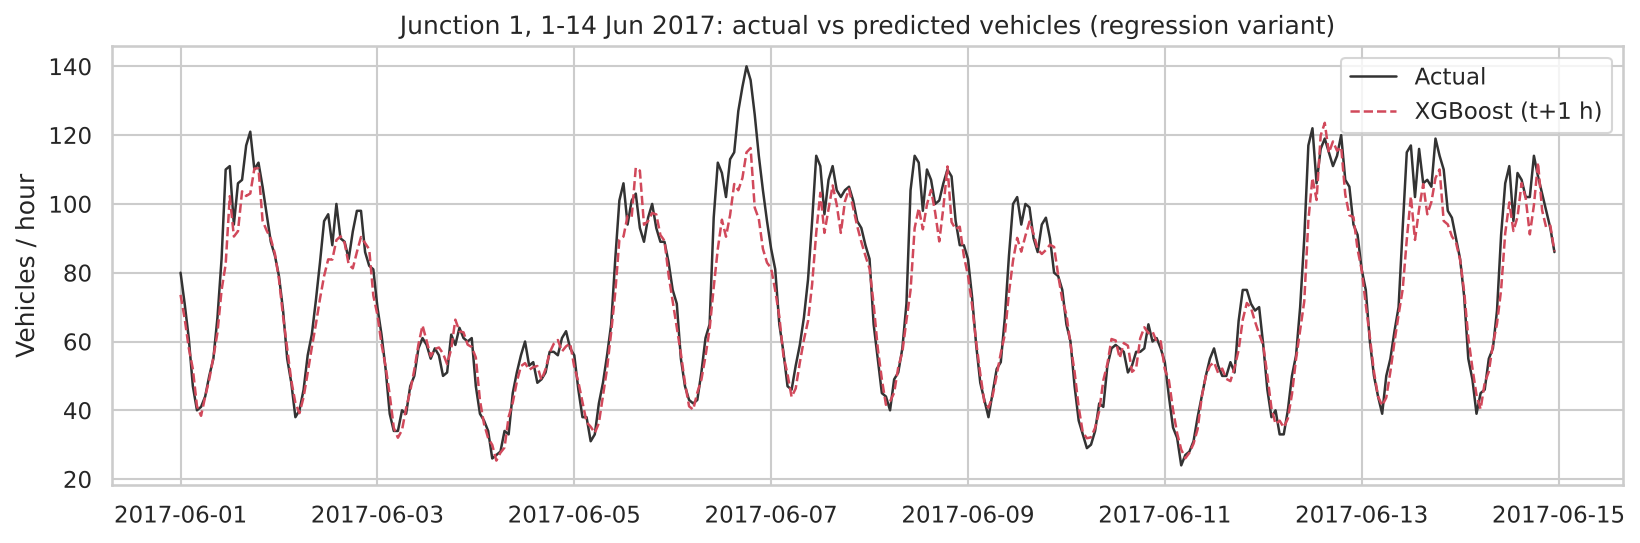

,model,RMSE,MAE,MAPE_%
0,Persistence (naive),5.949,3.915,22.344
1,Random Forest,4.825,2.878,17.930
2,XGBoost,4.832,2.895,17.053


In [12]:
reg, rpreds = M.train_regressors(model_df, feats, train, val, test)
M.plot_regression(model_df, test, rpreds); show("14_regression_actual_vs_pred.png")
reg.round(3)

## 6. Explainability (SHAP on XGBoost)

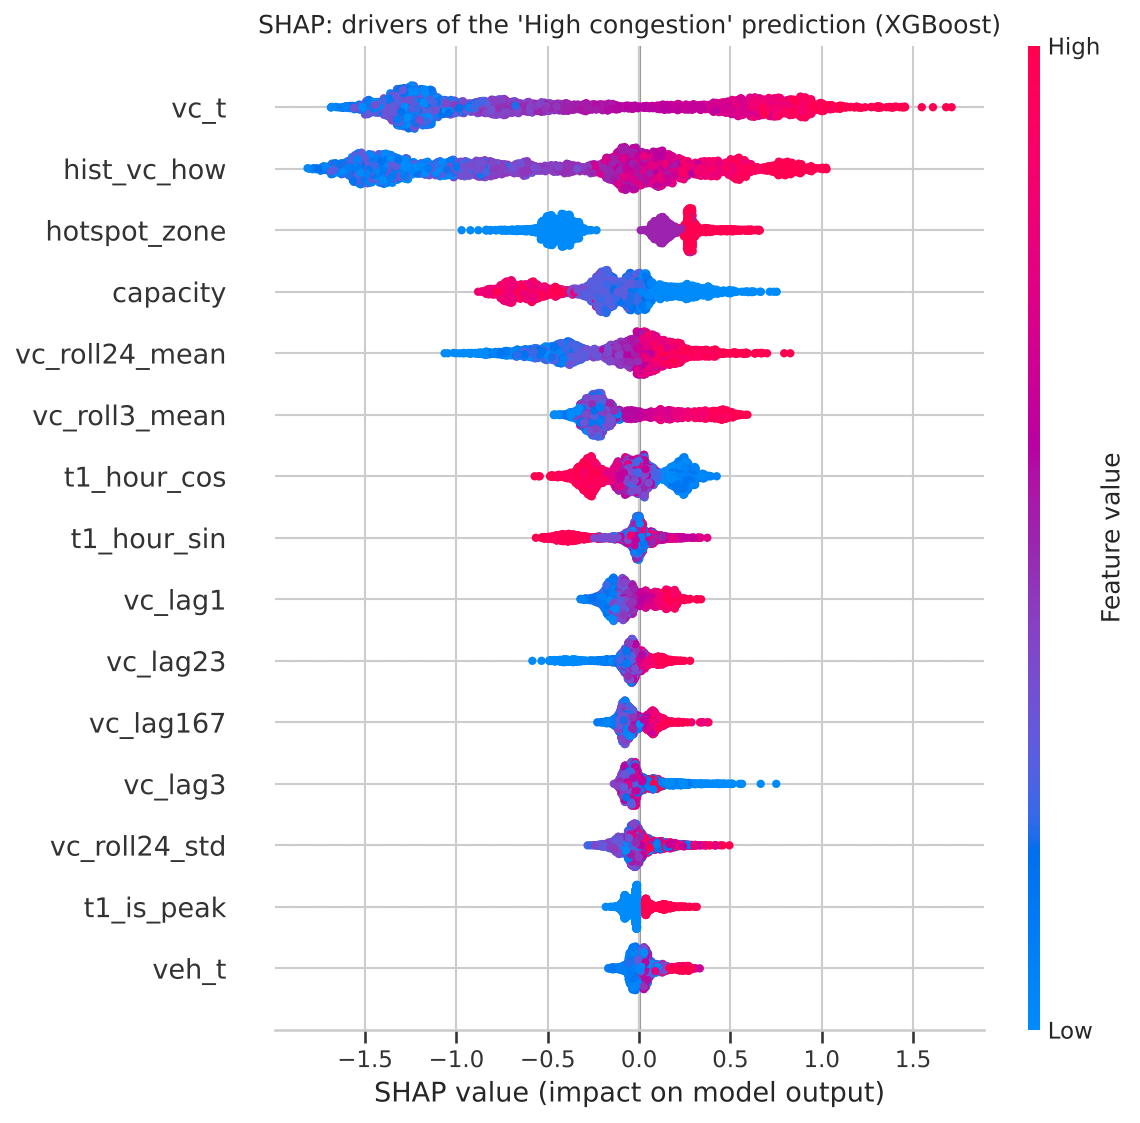

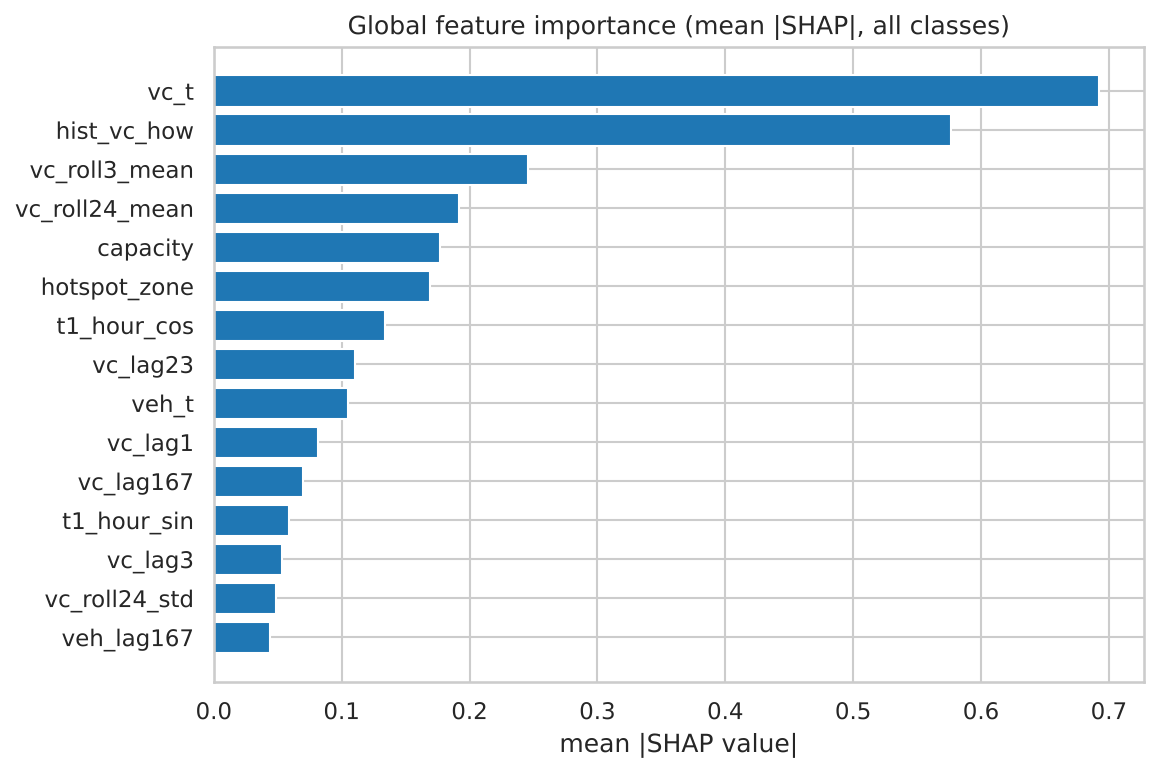

,feature,mean_abs_shap_all,mean_abs_shap_high,share_%
7,vc_t,0.6927,0.8825,22.4256
27,hist_vc_how,0.5762,0.6922,18.6549
18,vc_roll3_mean,0.2456,0.2382,7.9506
19,vc_roll24_mean,0.1914,0.2425,6.1970
17,capacity,0.1765,0.2814,5.7157
28,hotspot_zone,0.1693,0.3451,5.4826
1,t1_hour_cos,0.1343,0.1695,4.3468
11,vc_lag23,0.1106,0.0805,3.5801
13,veh_t,0.1053,0.0558,3.4097
8,vc_lag1,0.0812,0.1162,2.6295


In [13]:
imp = M.shap_analysis(models["XGBoost"], model_df, feats, test)
show("15_shap_summary_high.png", 700); show("16_shap_bar.png", 650)
imp.head(12)

**Main drivers of next-hour congestion**
- current load (`vc_t`)
- the junction's usual load at that hour of the week (`hist_vc_how`)
- short rolling averages
- capacity
- the K-Means **hotspot zone**
- hour of day

In short, recent state plus the recurring weekly pattern explain most of the prediction.

## 7. Congestion-aware route recommendation
**Road network:** 21 well-known Bengaluru junctions (Silk Board, Marathahalli, Hebbal, MG Road, CMRIT…) and 33 road links. Road length = haversine × 1.3.

**Simulation link to the data:** each node takes the traffic *profile* of one dataset junction according to its road role:
- J1: ORR / highway
- J2: arterial
- J3: CBD
- J4: local / peripheral

**Edge travel time** = length / (free-flow speed 25–45 km/h × speed factor). The speed factor is 1.0, 0.6 or 0.3 for Low, Moderate or High.

**Planners compared**
1. Shortest distance (static baseline)
2. Historical-average congestion
3. **ML-predicted congestion** (XGBoost probabilities, expected speed factor)
4. Oracle (perfect knowledge, an upper bound)

Every route is **scored with the congestion that actually happened**. Routes are found with **Dijkstra and A\*** (admissible straight-line heuristic).

In [14]:
proba = models["XGBoost"].predict_proba(model_df.loc[test, feats])
te = model_df.loc[test, ["Junction", "target_time", "target_class", "hist_vc_how"]].copy()
te["hist_class"] = M.vc_to_class(te.hist_vc_how); te[["p_low", "p_moderate", "p_high"]] = proba
states = {}
for t, g in te.groupby("target_time"):
    if g.Junction.nunique() == 4:
        states[t] = {"actual": {r.Junction: R.one_hot(r.target_class) for r in g.itertuples()},
                     "historical": {r.Junction: R.one_hot(r.hist_class) for r in g.itertuples()},
                     "predicted": {r.Junction: np.array([r.p_low, r.p_moderate, r.p_high]) for r in g.itertuples()}}
trips = R.evaluate_routing(states, n_hours=300)
summary = R.summarise_routing(trips); print(json.dumps(summary, indent=1))

{
 "historical_avg": {
  "mean_saving_%": 0.3,
  "median_saving_%": 0.0,
  "p90_saving_%": 0.0,
  "trips_faster_%": 9.2,
  "trips_slower_%": 7.4,
  "mean_minutes_saved": 0.61
 },
 "ml_predicted": {
  "mean_saving_%": 1.49,
  "median_saving_%": 0.0,
  "p90_saving_%": 2.96,
  "trips_faster_%": 10.7,
  "trips_slower_%": 5.6,
  "mean_minutes_saved": 1.39
 },
 "oracle_actual": {
  "mean_saving_%": 2.25,
  "median_saving_%": 0.0,
  "p90_saving_%": 7.34,
  "trips_faster_%": 15.0,
  "trips_slower_%": 0.0,
  "mean_minutes_saved": 1.89
 },
 "ml_when_route_changes": {
  "share_of_trips_%": 16.3,
  "mean_saving_%": 9.11
 },
 "ml_share_of_oracle_gain_%": 73.3,
 "n_trips": 126000,
 "n_hours": 300
}


{'origin': 'Nagawara', 'dest': 'Domlur', 'time': '2017-05-25 19:00:00', 'shortest_path': ['Nagawara', 'Tin Factory', 'Indiranagar', 'Domlur'], 'ml_path': ['Nagawara', 'Hebbal', 'Mekhri Circle', 'MG Road', 'Domlur'], 'shortest_actual_min': 94.7, 'ml_actual_min': 70.2}


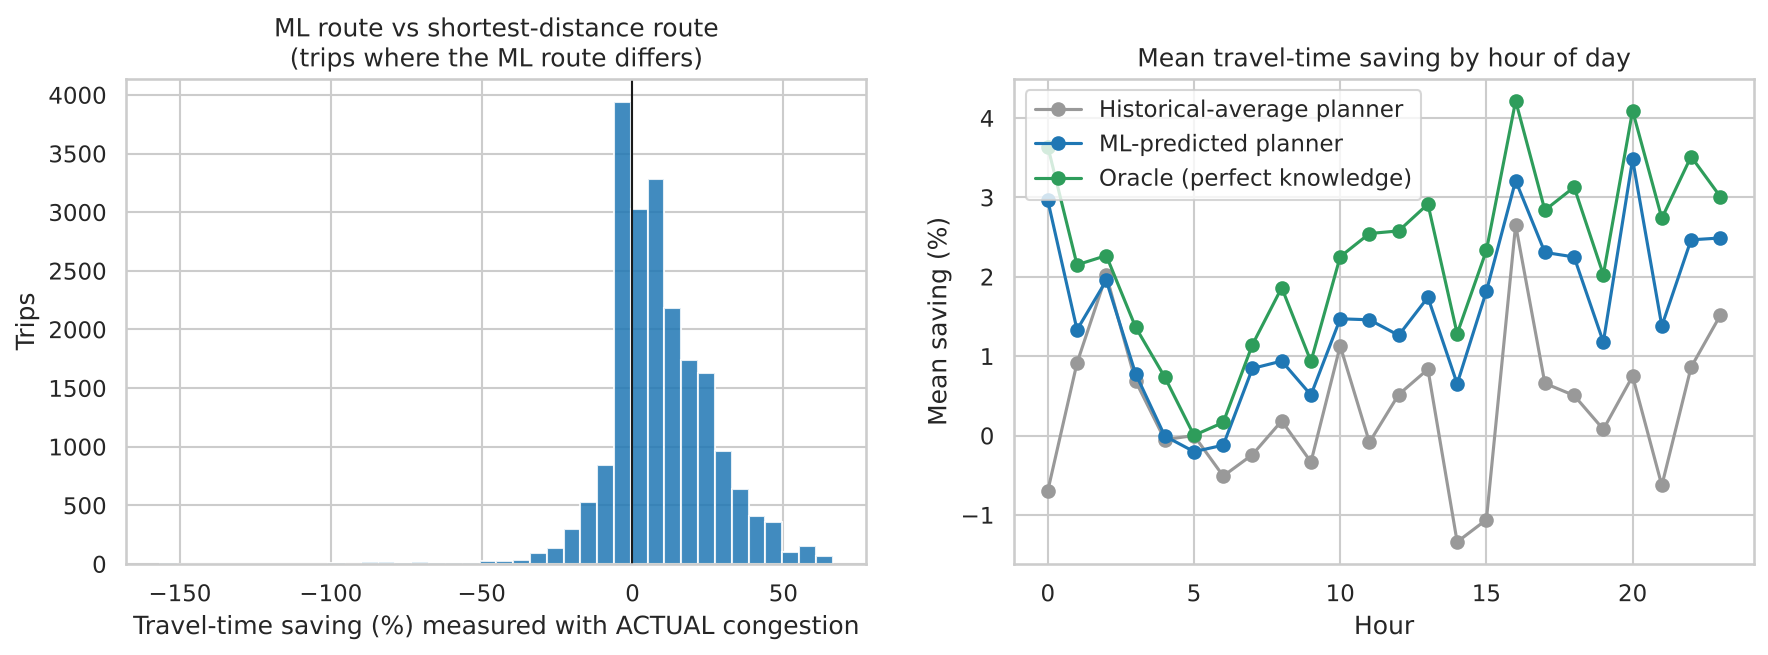

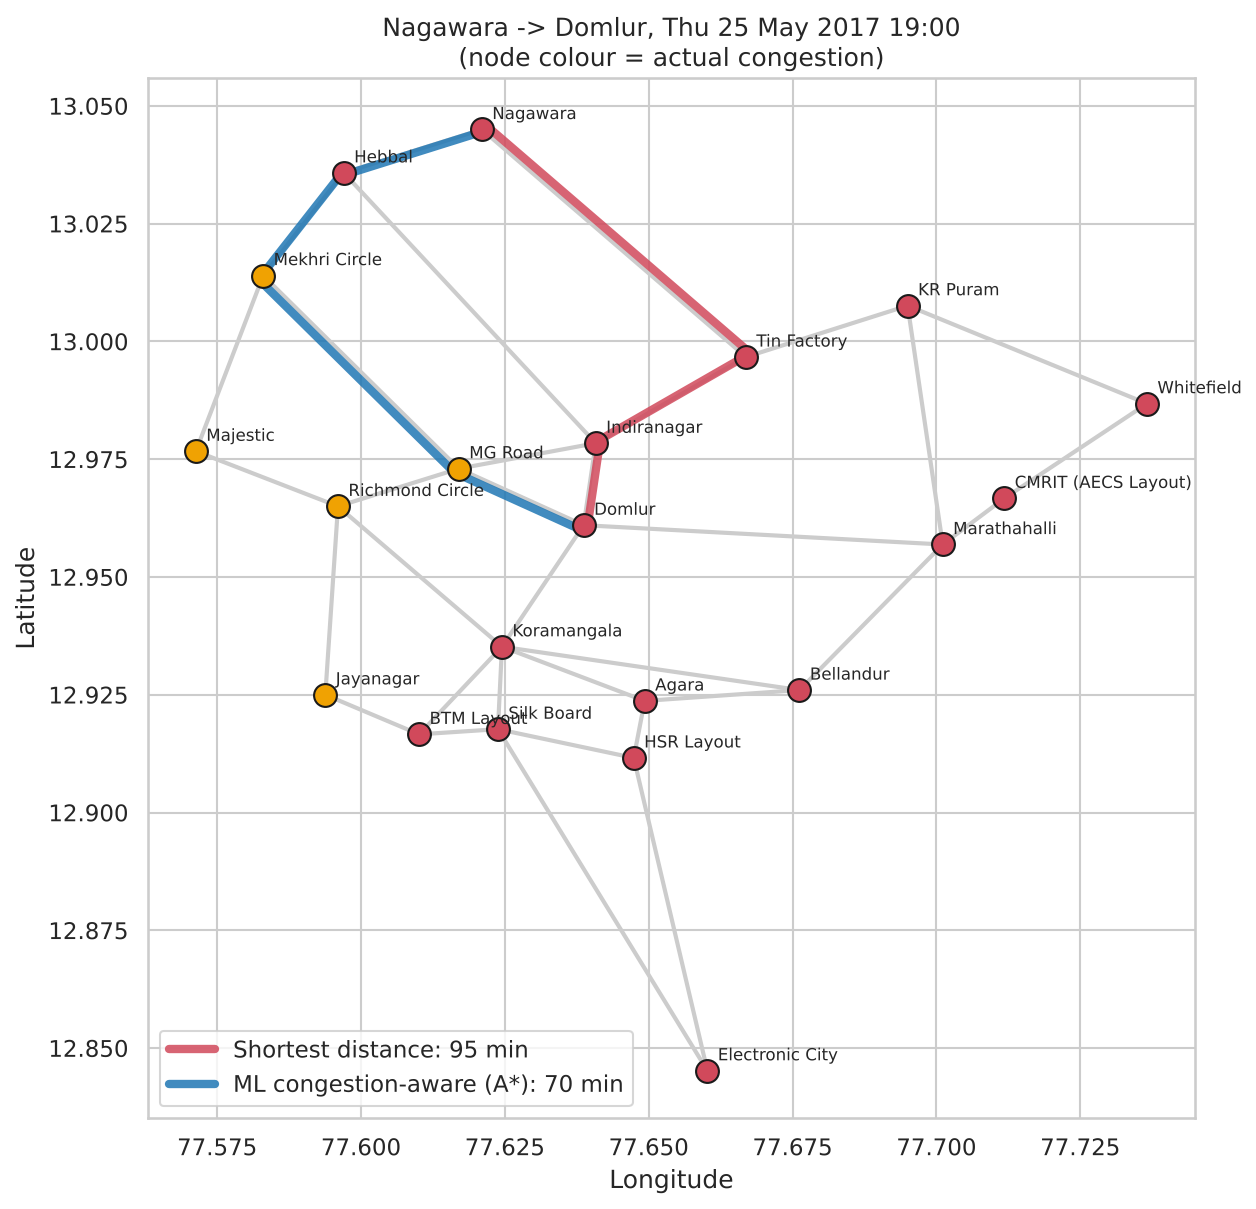

In [15]:
PR.plot_savings(trips)
th = pd.to_datetime(trips.time).dt.hour; peak = th.isin([8, 9, 10, 17, 18, 19, 20])
cand = trips[peak & trips.ml_route_differs & (trips["ml_predicted_saving_%"] > 0)].sort_values("ml_predicted_saving_%").reset_index(drop=True)
ex = cand.iloc[int(len(cand) * 0.75)]
_, example = PR.plot_route_example(states[ex.time]["actual"], states[ex.time]["predicted"], ex.origin, ex.dest, ex.time)
print(example); show("18_routing_savings.png"); show("17_route_example.png", 650)

## 8. Evaluation summary
- **Prediction:** ensemble and sequence models beat both naive baselines on every metric (Section 4).
- **Routing:**
  - The ML planner changes the route for about 16% of trips. When it does, it saves about 9% travel time on average.
  - It captures about 73% of the gain that perfect knowledge would give.
  - The historical-average planner gains almost nothing and often picks *slower* routes.
  - Average saving over *all* trips is modest (≈1.5%), because most trips have no better alternative in a 21-node graph.
- **Dijkstra vs A\*:** identical optimal costs. A\* expands fewer nodes and is slightly faster.

## 9. Role in smart transportation
- **Commuters, cabs and last-mile logistics:** next-hour forecasts allow rerouting *before* congestion forms.
- **Traffic police and BTP / city authorities:** hotspot zones show where and when to deploy, re-time signals and prioritise capacity upgrades.
- **Explainable outputs (SHAP)** help operators trust and audit the system.
- **Limitations and next steps:**
  - only 4 anonymous junctions, with no weather or incident data
  - simulated road graph and speed-congestion mapping
  - next steps: live GPS/IoT feeds, a full OpenStreetMap network, Graph Neural Networks